# Netflix Movies & TV Shows: Data Analysis

**A beginner-friendly exploratory data analysis project**

This notebook uses the Netflix Movies and TV Shows dataset from [Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows) to explore the titles, release years, countries, genres, ratings, durations, and dates when titles were added to Netflix. All conclusions below are calculated from the CSV loaded in this notebook.

## Project objectives

- Compare the number of Movies and TV Shows.
- Explore release years and the timing of Netflix additions.
- Find common countries, genres, ratings, directors, and actors.
- Describe movie runtimes and TV show season counts.
- Communicate patterns with clear charts and careful caveats.

The CSV has 12 columns: `show_id` (identifier), `type`, `title`, `director`, `cast`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in` (genres/categories), and `description`.

> **Dataset note:** the CSV is not included in this project for redistribution. Download `netflix_titles.csv` from the Kaggle page above (Kaggle may require an account), review the dataset page's current license/terms, and place the file in `data/netflix_titles.csv`. The supplied local copy is ignored by Git.

## 1. Import libraries

`pandas` works with table-shaped data, `numpy` supports numerical calculations, `matplotlib` and `seaborn` create charts, and `os` helps manage folders and file paths.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent style so the charts look related.
sns.set_theme(style="whitegrid", context="notebook")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.3.3
numpy: 2.3.5


## 2. Load the dataset

A DataFrame is a table in pandas. The path is relative to this project folder, so run the notebook with `netflix-data-analysis` as the working folder (the VS Code default when opening this folder).

In [2]:
DATA_PATH = os.path.join("data", "netflix_titles.csv")

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Download netflix_titles.csv from "
        "https://www.kaggle.com/datasets/shivamb/netflix-shows and place it in the data/ folder."
    )

# Keep the raw data unchanged. We will make a separate copy for cleaning.
raw_df = pd.read_csv(DATA_PATH)

print("First five rows:")
display(raw_df.head())
print("Last five rows:")
display(raw_df.tail())

First five rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Last five rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [3]:
print("Dataset shape (rows, columns):", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())
print("\nData types:")
print(raw_df.dtypes)

Dataset shape (rows, columns): (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


## 3. Explore the data

These checks help us understand the table before changing it. `info()` summarizes data types and non-missing values, while `describe()` summarizes each column. Missing values are not automatically errors; we will decide how to handle each one based on its meaning.

In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
# include="all" also summarizes text columns; some numeric statistics will be blank for text.
display(raw_df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing_summary = raw_df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing_summary.to_frame(name="missing_count"))
print("Exact duplicate rows:", raw_df.duplicated().sum())
print("Duplicate show_id values:", raw_df["show_id"].duplicated().sum())

Missing values by column:


,missing_count
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3
show_id,0
type,0
title,0
release_year,0


Exact duplicate rows: 0
Duplicate show_id values: 0


In [7]:
# Unique values are useful for checking the categories and date/year ranges.
for column in ["type", "rating", "release_year"]:
    print(f"\n{column}: {raw_df[column].nunique(dropna=True)} unique values")
    print(raw_df[column].value_counts(dropna=False).head(10))


type: 2 unique values
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

rating: 17 unique values
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64

release_year: 74 unique values
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


## 4. Clean a working copy

We keep `raw_df` intact and make `cleaned_df` for analysis. Exact duplicate rows are redundant. `show_id` is intended to identify one title, so if an identifier appears more than once, we keep its first occurrence and report the count. Missing people/place/classification fields get the clear label `Not Listed`. Three duration-like strings in the rating column are also reclassified as `Not Listed` in the cleaned copy because they are not valid content ratings; the source values remain in `raw_df`; missing dates remain missing (`NaT`) because inventing a date would distort time trends. The original `duration` text is retained while separate numeric columns are created for movie minutes and TV seasons. Missing or unparseable durations remain missing; the notebook does not guess values.

In [8]:
cleaned_df = raw_df.drop_duplicates().copy()
exact_duplicates_removed = len(raw_df) - len(cleaned_df)

# Keep one row per title identifier if any repeated IDs are present.
duplicate_ids_removed = cleaned_df["show_id"].duplicated().sum()
cleaned_df = cleaned_df.drop_duplicates(subset="show_id", keep="first").copy()

print("Exact duplicate rows removed:", exact_duplicates_removed)
print("Rows removed for repeated show_id:", duplicate_ids_removed)
print("Raw rows remain unchanged:", len(raw_df), "| Cleaned rows:", len(cleaned_df))

Exact duplicate rows removed: 0
Rows removed for repeated show_id: 0
Raw rows remain unchanged: 8807 | Cleaned rows: 8807


In [9]:
# Fill descriptive text fields with an explicit label rather than dropping those titles.
text_columns = ["director", "cast", "country", "rating", "listed_in"]
for column in text_columns:
    cleaned_df[column] = cleaned_df[column].fillna("Not Listed")

# Some source rating cells contain duration-like text, not a content rating.
rating_is_duration = cleaned_df["rating"].astype("string").str.fullmatch(
    r"\d+\s+min", case=False, na=False
)
invalid_rating_count = int(rating_is_duration.sum())
cleaned_df.loc[rating_is_duration, "rating"] = "Not Listed"
print("Duration-like rating entries reclassified as Not Listed:", invalid_rating_count)

# Parse mixed written date formats safely. Missing or invalid dates become NaT.
cleaned_df["date_added"] = pd.to_datetime(
    cleaned_df["date_added"], errors="coerce", format="mixed"
)
cleaned_df["added_year"] = cleaned_df["date_added"].dt.year.astype("Int64")
cleaned_df["added_month"] = cleaned_df["date_added"].dt.month.astype("Int64")
cleaned_df["added_month_name"] = cleaned_df["date_added"].dt.month_name()

# The source duration text mixes units. Extract its number only for the matching title type.
duration_number = pd.to_numeric(
    cleaned_df["duration"].astype("string").str.extract(r"(\d+)", expand=False),
    errors="coerce",
)
cleaned_df["movie_duration_minutes"] = duration_number.where(cleaned_df["type"].eq("Movie"))
cleaned_df["tv_seasons"] = duration_number.where(cleaned_df["type"].eq("TV Show"))

print("Cleaned data sample:")
display(cleaned_df[["title", "type", "date_added", "added_year", "added_month_name", "duration", "movie_duration_minutes", "tv_seasons"]].head())
print("Missing date_added values after safe parsing:", cleaned_df["date_added"].isna().sum())

Duration-like rating entries reclassified as Not Listed: 3
Cleaned data sample:


,title,type,date_added,added_year,added_month_name,duration,movie_duration_minutes,tv_seasons
0,Dick Johnson Is Dead,Movie,2021-09-25,2021,September,90 min,90,<NA>
1,Blood & Water,TV Show,2021-09-24,2021,September,2 Seasons,<NA>,2
2,Ganglands,TV Show,2021-09-24,2021,September,1 Season,<NA>,1
3,Jailbirds New Orleans,TV Show,2021-09-24,2021,September,1 Season,<NA>,1
4,Kota Factory,TV Show,2021-09-24,2021,September,2 Seasons,<NA>,2


Missing date_added values after safe parsing: 10


In [10]:
def split_list_field(value):
    """Split comma-separated values and remove extra spaces."""
    if pd.isna(value):
        return []
    return [item.strip() for item in str(value).split(",") if item.strip()]

# Each title can belong to multiple countries or genres, so explode creates one item per row.
country_rows = cleaned_df[["show_id", "title", "country"]].copy()
country_rows["country"] = country_rows["country"].apply(split_list_field)
country_rows = country_rows.explode("country")
country_rows = country_rows[country_rows["country"].ne("Not Listed")]

genre_rows = cleaned_df[["show_id", "title", "listed_in"]].copy()
genre_rows["genre"] = genre_rows["listed_in"].apply(split_list_field)
genre_rows = genre_rows.explode("genre")
genre_rows = genre_rows[genre_rows["genre"].ne("Not Listed")]

print("Country entries for analysis:", len(country_rows))
print("Genre entries for analysis:", len(genre_rows))

Country entries for analysis: 10012
Genre entries for analysis: 19323


## 5. Exploratory Data Analysis (EDA)

Each question is answered with pandas operations. A title may list multiple countries or genres, so those tables count a title once for each listed item; their totals can exceed the number of titles.

### 1–2. How many Movies and TV Shows are listed, and which type is more common?

In [11]:
type_counts = cleaned_df["type"].value_counts()
type_percentages = (type_counts / len(cleaned_df) * 100).round(1)
type_summary = pd.DataFrame({"titles": type_counts, "percent_of_catalog": type_percentages})
display(type_summary)
print("More common type:", type_counts.idxmax(), "(", f"{type_counts.max():,}", "titles )")

,titles,percent_of_catalog
type,,
Movie,6131,69.6
TV Show,2676,30.4


More common type: Movie ( 6,131 titles )


`value_counts()` counts each title type. The percentage uses the cleaned title count as its denominator, so the two shares should total about 100%.

### 3. How has Netflix content grown by release year?

In [12]:
release_year_counts = (
    cleaned_df.dropna(subset=["release_year"])
    .groupby("release_year")["show_id"]
    .nunique()
    .sort_index()
)
display(release_year_counts.tail(15).to_frame(name="titles_released"))
print("Most represented release year:", int(release_year_counts.idxmax()), "with", int(release_year_counts.max()), "titles")

,titles_released
release_year,
2007,88
2008,136
2009,152
2010,194
2011,185
2012,237
2013,288
2014,352
2015,560


Most represented release year: 2018 with 1147 titles


Release year is the year a title was originally released, not the year it arrived on Netflix. This describes the catalog in this snapshot, not Netflix production or yearly additions.

### 4. Which countries have the most titles?

In [13]:
country_counts = country_rows["country"].value_counts()
top_countries = country_counts.head(10)
display(top_countries.to_frame(name="titles_listed"))

,titles_listed
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


Because a title can have several countries, a title may contribute to more than one country count.

### 5. What are the most common genres?

In [14]:
genre_counts = genre_rows["genre"].value_counts()
top_genres = genre_counts.head(10)
display(top_genres.to_frame(name="titles_listed"))

,titles_listed
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


The dataset calls this field `listed_in`; it combines genre/category labels. A title can be counted in multiple categories.

### 6. Which content ratings are most common?

In [15]:
rating_counts = cleaned_df["rating"].value_counts()
display(rating_counts.to_frame(name="titles"))

,titles
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


Ratings are classifications in the source dataset. `Not Listed` makes titles with missing classifications visible rather than silently removing them.

### 7. What is the average movie duration?

In [16]:
movie_durations = cleaned_df.loc[cleaned_df["type"].eq("Movie"), "movie_duration_minutes"].dropna()
if movie_durations.empty:
    print("No valid movie durations are available.")
else:
    print("Movies with a parsed duration:", len(movie_durations))
    print("Average duration (minutes):", round(movie_durations.mean(), 1))
    print("Median duration (minutes):", round(movie_durations.median(), 1))

Movies with a parsed duration: 6128
Average duration (minutes): 99.6
Median duration (minutes): 98.0


Only numeric movie runtimes are included; TV season values and missing durations are excluded from this calculation.

### 8. Which TV show season count is most common?

In [17]:
season_counts = cleaned_df.loc[cleaned_df["type"].eq("TV Show"), "tv_seasons"].dropna().astype(int).value_counts().sort_index()
display(season_counts.to_frame(name="TV_shows"))
if not season_counts.empty:
    print("Most common season count:", int(season_counts.idxmax()), "season(s)")

,TV_shows
tv_seasons,
1,1793
2,425
3,199
4,95
5,65
6,33
7,23
8,17
9,9


Most common season count: 1 season(s)


The number is extracted from the original duration text only for TV Shows. It is not a measure of episode count.

### 9. Which directors and actors have the most titles?

In [18]:
director_titles = cleaned_df.loc[cleaned_df["director"].ne("Not Listed"), ["show_id", "director"]].copy()
director_titles["director"] = director_titles["director"].apply(split_list_field)
director_titles = director_titles.explode("director")
top_directors = director_titles["director"].value_counts().head(10)
print("Top directors:")
display(top_directors.to_frame(name="titles"))

actor_titles = cleaned_df.loc[cleaned_df["cast"].ne("Not Listed"), ["show_id", "cast"]].copy()
actor_titles["cast"] = actor_titles["cast"].apply(split_list_field)
actor_titles = actor_titles.explode("cast")
top_actors = actor_titles["cast"].value_counts().head(10)
print("Top actors:")
display(top_actors.to_frame(name="titles"))

Top directors:


,titles
director,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Jay Chapman,12
Youssef Chahine,12


Top actors:


,titles
cast,
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29


Director and cast lists may contain multiple names per title. These counts describe appearances in this dataset, not popularity, screen time, or complete career credits.

### 10. Which months and dates have the most Netflix additions?

In [19]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
added_by_month = cleaned_df["added_month_name"].value_counts().reindex(month_order, fill_value=0)
display(added_by_month.to_frame(name="titles_added"))
print("Month with the most additions:", added_by_month.idxmax(), "(", f"{added_by_month.max():,}", "titles )")

monthly_additions = cleaned_df.dropna(subset=["date_added"]).copy()
monthly_additions["added_period"] = monthly_additions["date_added"].dt.to_period("M")
monthly_by_type = monthly_additions.groupby(["added_period", "type"])["show_id"].nunique().unstack(fill_value=0)
display(monthly_by_type.tail(12))

,titles_added
added_month_name,
January,738
February,563
March,742
April,764
May,632
June,728
July,827
August,755
September,770


Month with the most additions: July ( 827 titles )


type,Movie,TV Show
added_period,,
2020-10,116,51
2020-11,103,51
2020-12,101,68
2021-01,96,36
2021-02,65,44
2021-03,75,37
2021-04,135,53
2021-05,94,38
2021-06,124,83


Month-of-year counts combine all dates available in the file. The monthly time series uses parsed `date_added`; missing dates cannot be placed on that timeline.

## 6. Visualizations

The charts below are saved as PNG files in `outputs/charts/`. If you change data or styling, rerun the notebook cells in order to refresh them.

In [20]:
CHART_DIR = os.path.join("outputs", "charts")
os.makedirs(CHART_DIR, exist_ok=True)

# Small helper to apply consistent spacing and save each chart.
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(CHART_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

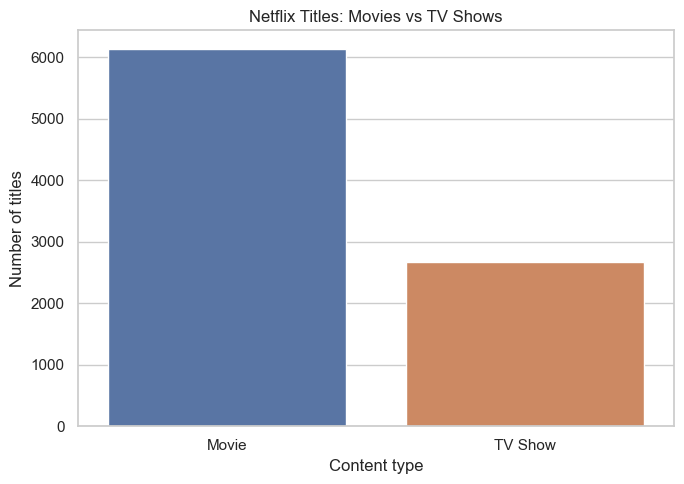

In [21]:
plt.figure(figsize=(7, 5))
sns.countplot(data=cleaned_df, x="type", order=type_counts.index, hue="type", legend=False)
plt.title("Netflix Titles: Movies vs TV Shows")
plt.xlabel("Content type")
plt.ylabel("Number of titles")
save_chart("01_movies_vs_tv_shows.png")

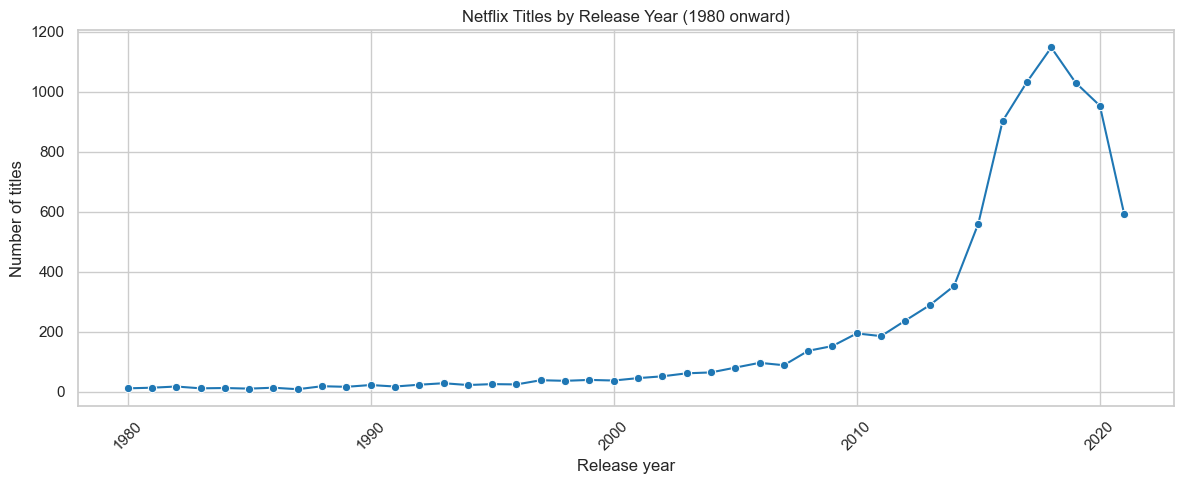

In [22]:
release_year_plot = release_year_counts[release_year_counts.index >= 1980]
plt.figure(figsize=(12, 5))
sns.lineplot(x=release_year_plot.index, y=release_year_plot.values, marker="o", color="#1f77b4")
plt.title("Netflix Titles by Release Year (1980 onward)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.xticks(rotation=45)
save_chart("02_titles_by_release_year.png")

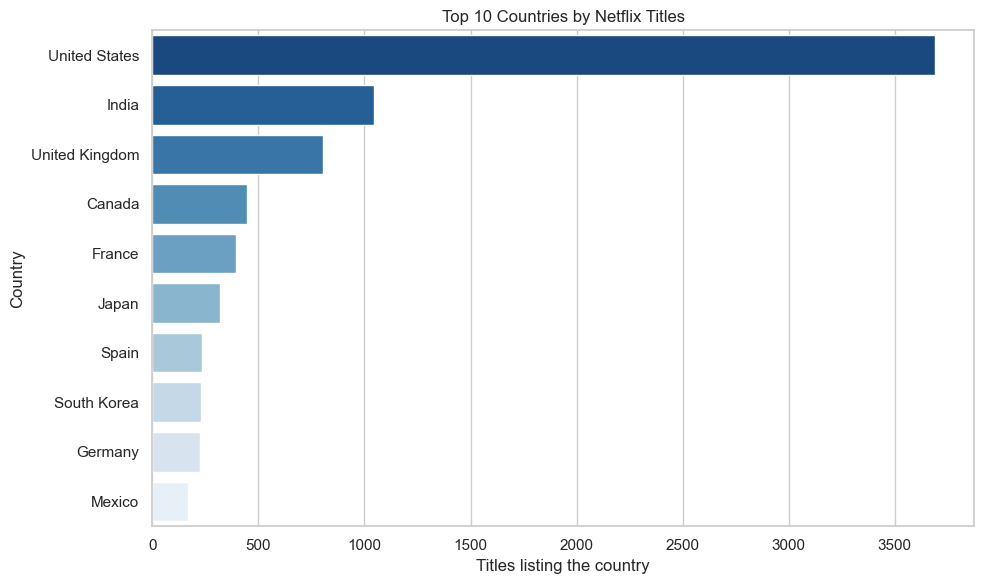

In [23]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, legend=False, palette="Blues_r")
plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Titles listing the country")
plt.ylabel("Country")
save_chart("03_top_10_countries.png")

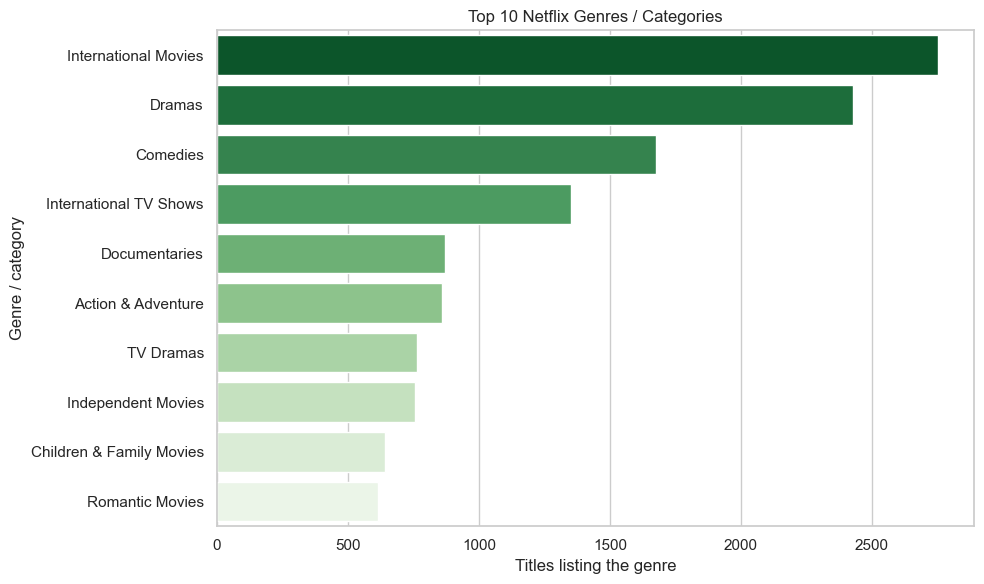

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index, legend=False, palette="Greens_r")
plt.title("Top 10 Netflix Genres / Categories")
plt.xlabel("Titles listing the genre")
plt.ylabel("Genre / category")
save_chart("04_top_10_genres.png")

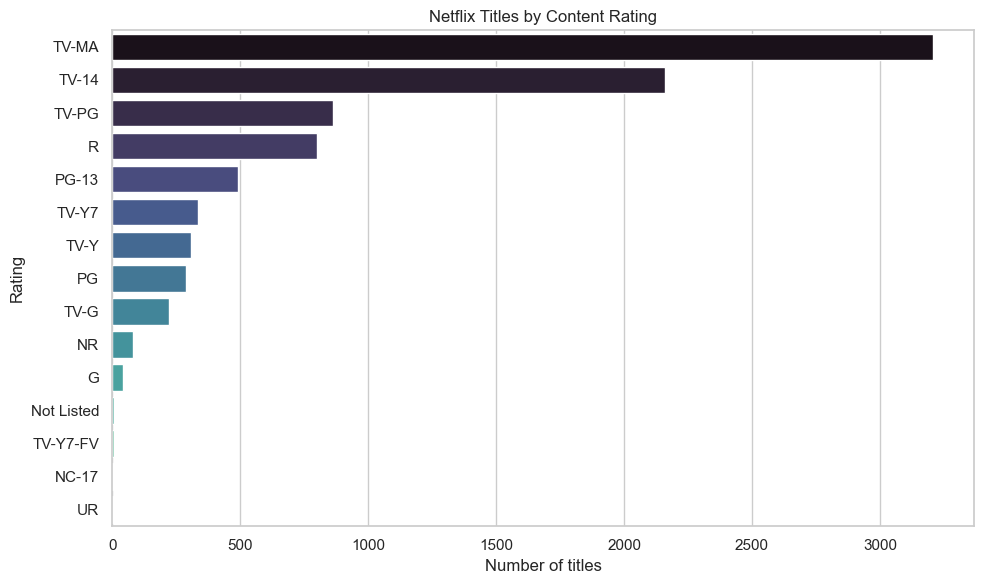

In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index, hue=rating_counts.index, legend=False, palette="mako")
plt.title("Netflix Titles by Content Rating")
plt.xlabel("Number of titles")
plt.ylabel("Rating")
save_chart("05_content_ratings.png")

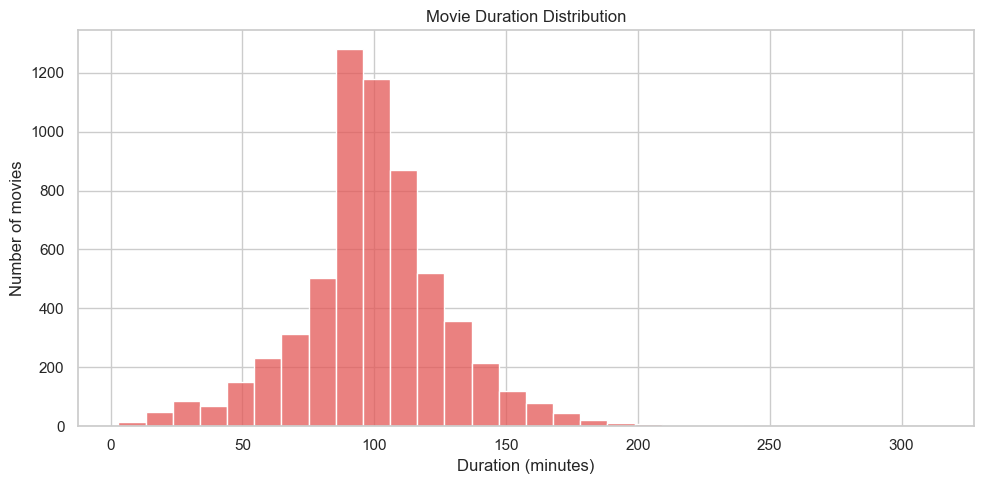

In [26]:
plt.figure(figsize=(10, 5))
sns.histplot(movie_durations, bins=30, color="#e45756", edgecolor="white")
plt.title("Movie Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of movies")
save_chart("06_movie_duration_distribution.png")

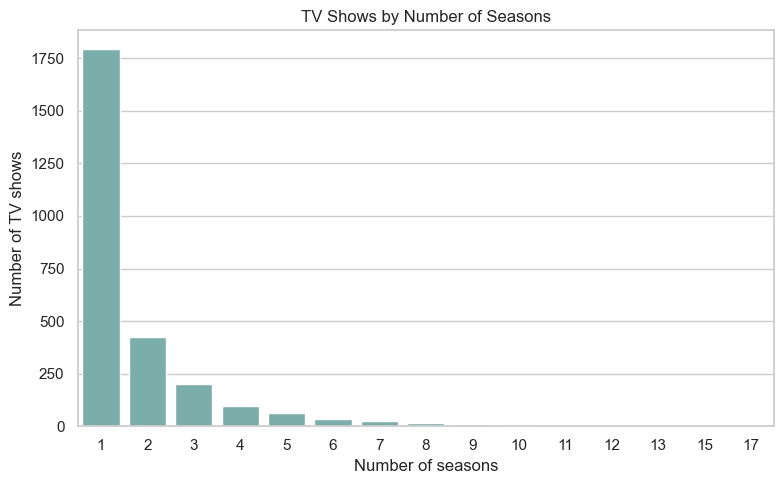

In [27]:
tv_seasons = cleaned_df.loc[cleaned_df["type"].eq("TV Show"), "tv_seasons"].dropna().astype(int)
plt.figure(figsize=(8, 5))
sns.countplot(x=tv_seasons, color="#72b7b2")
plt.title("TV Shows by Number of Seasons")
plt.xlabel("Number of seasons")
plt.ylabel("Number of TV shows")
save_chart("07_tv_show_seasons.png")

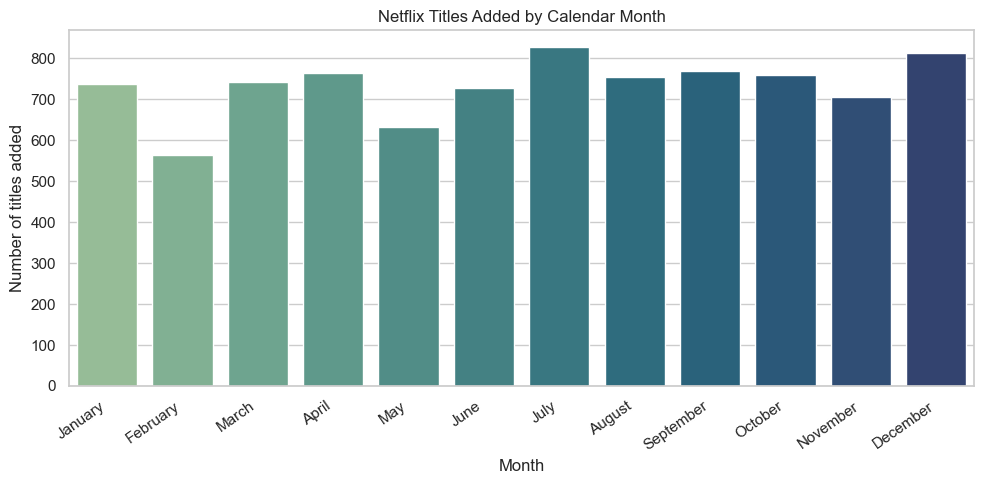

In [28]:
plt.figure(figsize=(10, 5))
sns.barplot(x=added_by_month.index, y=added_by_month.values, hue=added_by_month.index, legend=False, palette="crest")
plt.title("Netflix Titles Added by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Number of titles added")
plt.xticks(rotation=35, ha="right")
save_chart("08_additions_by_month.png")

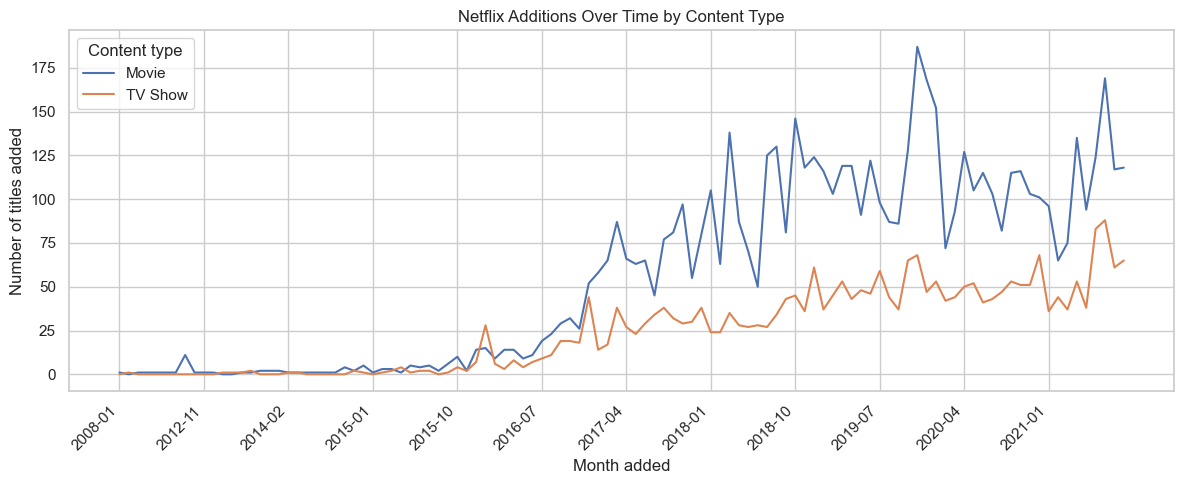

In [29]:
plt.figure(figsize=(12, 5))
for content_type in ["Movie", "TV Show"]:
    if content_type in monthly_by_type.columns:
        sns.lineplot(x=monthly_by_type.index.astype(str), y=monthly_by_type[content_type], label=content_type)
plt.title("Netflix Additions Over Time by Content Type")
plt.xlabel("Month added")
plt.ylabel("Number of titles added")
plt.xticks(ticks=range(0, len(monthly_by_type), max(1, len(monthly_by_type) // 12)), rotation=45, ha="right")
plt.legend(title="Content type")
save_chart("09_additions_over_time_by_type.png")

## 7. Key business insights

These statements are generated from the result tables above whenever the notebook runs. They describe this dataset snapshot only; they are not claims about Netflix today.

In [30]:
movie_count = int(type_counts.get("Movie", 0))
tv_count = int(type_counts.get("TV Show", 0))
movie_share = (movie_count / len(cleaned_df) * 100) if len(cleaned_df) else 0

print(f"1. The dataset contains {movie_count:,} Movies and {tv_count:,} TV Shows; Movies make up {movie_share:.1f}% of listed titles.")
if not top_countries.empty:
    print(f"2. {top_countries.index[0]} is the most frequently listed country ({top_countries.iloc[0]:,} title-country entries).")
if not top_genres.empty:
    print(f"3. {top_genres.index[0]} is the most frequently listed genre/category ({top_genres.iloc[0]:,} titles).")
if not rating_counts.empty:
    print(f"4. {rating_counts.index[0]} is the most frequent rating label ({rating_counts.iloc[0]:,} titles).")
if not release_year_counts.empty:
    print(f"5. Release year {int(release_year_counts.idxmax())} has the most titles in this snapshot ({int(release_year_counts.max()):,}); release year is not the same as Netflix addition year.")
if not added_by_month.empty:
    print(f"6. {added_by_month.idxmax()} has the most recorded additions by calendar month ({int(added_by_month.max()):,}); this compares months pooled across years.")
if not movie_durations.empty:
    print(f"7. Parsed Movies average {movie_durations.mean():.1f} minutes (median {movie_durations.median():.1f}) among {len(movie_durations):,} titles with a duration.")
if not season_counts.empty:
    print(f"8. The most common TV show length is {int(season_counts.idxmax())} season(s) ({int(season_counts.max()):,} shows).")
if not top_directors.empty:
    print(f"9. {top_directors.index[0]} has the most director credits in the listed data ({int(top_directors.iloc[0]):,} titles).")
else:
    print("9. No director credits were available to rank.")

1. The dataset contains 6,131 Movies and 2,676 TV Shows; Movies make up 69.6% of listed titles.
2. United States is the most frequently listed country (3,690 title-country entries).
3. International Movies is the most frequently listed genre/category (2,752 titles).
4. TV-MA is the most frequent rating label (3,207 titles).
5. Release year 2018 has the most titles in this snapshot (1,147); release year is not the same as Netflix addition year.
6. July has the most recorded additions by calendar month (827); this compares months pooled across years.
7. Parsed Movies average 99.6 minutes (median 98.0) among 6,128 titles with a duration.
8. The most common TV show length is 1 season(s) (1,793 shows).
9. Rajiv Chilaka has the most director credits in the listed data (22 titles).


## 8. Conclusion, limitations, and next steps

### What this analysis teaches

The tables and charts show how to load a CSV into a pandas DataFrame, inspect and clean data without altering the source, split multi-value text fields, calculate grouped summaries, and create saved visualizations. Use the actual outputs above to describe the dominant content type, common categories, and date patterns.

### Limitations

- This is a dated snapshot from Kaggle, not a live Netflix catalog.
- Missing values and inconsistent source entries can affect counts.
- Titles can list multiple countries, genres, directors, or cast members; counts for those fields are not mutually exclusive.
- `date_added` is missing for some titles, and calendar-month patterns pool the dates available in the file.
- Release year, date added, and season counts do not measure viewing popularity, quality, or audience engagement.
- The dataset does not provide complete episode-level or viewership data.

### Possible future improvements

Add tests for cleaning functions, investigate changes over time by content type and country, compare ratings across content types, use episode-level data for TV shows, and add audience/viewership data from a properly licensed source. Confirm the Kaggle dataset's current terms before sharing the CSV itself.